# Sales Forecasting & Business Intelligence Platform

## Exploratory Data Analysis

### Objectives

This notebook explores the cleaned UCI Online Retail II dataset
from both business analytics and forecasting perspectives.

The analysis focuses on:

- Revenue performance
- Revenue growth
- Daily and monthly sales trends
- Geographic performance
- Product performance
- Customer behavior
- Returns and cancellations
- Sales seasonality
- Business insights

The findings will guide the feature engineering and forecasting
strategy in subsequent phases.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ml.data.loader import (
    load_daily_revenue,
    load_valid_sales,
    load_returns,
)


pd.set_option(
    "display.max_columns",
    None,
)

pd.set_option(
    "display.float_format",
    "{:,.2f}".format,
)

In [2]:
# Load processed datasets
daily = load_daily_revenue()

sales = load_valid_sales()

returns = load_returns()

print(
    f"Daily revenue : {daily.shape}"
)

print(
    f"Valid sales   : {sales.shape}"
)

print(
    f"Returns       : {returns.shape}"
)

D:\Research_Project\sales-forecasting-platform\src\sales_forecasting\data\loader.py:104: DtypeWarning: Columns (0: invoice_no) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(


Daily revenue : (739, 12)
Valid sales   : (1029609, 17)
Returns       : (19433, 18)


In [3]:
daily.head()

,date,gross_revenue,transaction_lines,invoices,return_revenue,return_lines,net_revenue,return_rate,year,month,day_of_week,is_weekend
0,2009-12-01,"54,351.23","3,068.00",119.00,"-1,340.47",110.00,"53,010.76",0.02,2009,12,1,0
1,2009-12-02,"63,172.58","3,208.00",115.00,-588.92,20.00,"62,583.66",0.01,2009,12,2,0
2,2009-12-03,"73,972.45","2,931.00",124.00,"-5,944.86",44.00,"68,027.59",0.08,2009,12,3,0
3,2009-12-04,"40,582.32","2,479.00",89.00,-386.52,27.00,"40,195.80",0.01,2009,12,4,0
4,2009-12-05,"9,803.05",400.00,30.00,0.00,0.00,"9,803.05",0.00,2009,12,5,1


In [4]:
# Data Validation
print(
    "Daily date range:",
    daily["date"].min(),
    "→",
    daily["date"].max(),
)

print(
    "Missing dates:",
    daily["date"].isna().sum(),
)

print(
    "Duplicate dates:",
    daily["date"].duplicated().sum(),
)

print(
    "Missing net revenue:",
    daily["net_revenue"].isna().sum(),
)

Daily date range: 2009-12-01 00:00:00 → 2011-12-09 00:00:00
Missing dates: 0
Duplicate dates: 0
Missing net revenue: 0


In [5]:
# KPI Overview - used for Power BI later
total_gross_revenue = (
    daily["gross_revenue"].sum()
)

total_return_revenue = (
    daily["return_revenue"].sum()
)

total_net_revenue = (
    daily["net_revenue"].sum()
)

total_invoices = (
    sales["invoice_no"].nunique()
)

total_customers = (
    sales["customer_id"]
    .nunique(dropna=True)
)

total_products = (
    sales["stock_code"].nunique()
)

total_countries = (
    sales["country"].nunique()
)

print("=" * 60)
print("BUSINESS PERFORMANCE OVERVIEW")
print("=" * 60)

print(
    f"Gross Revenue : "
    f"£{total_gross_revenue:,.2f}"
)

print(
    f"Returns       : "
    f"£{total_return_revenue:,.2f}"
)

print(
    f"Net Revenue   : "
    f"£{total_net_revenue:,.2f}"
)

print(
    f"Invoices      : "
    f"{total_invoices:,}"
)

print(
    f"Customers     : "
    f"{total_customers:,}"
)

print(
    f"Products      : "
    f"{total_products:,}"
)

print(
    f"Countries     : "
    f"{total_countries:,}"
)

BUSINESS PERFORMANCE OVERVIEW
Gross Revenue : £20,913,891.47
Returns       : £-1,524,161.95
Net Revenue   : £19,389,729.52
Invoices      : 40,079
Customers     : 5,878
Products      : 4,745
Countries     : 43


In [6]:
# Average Order Value
average_order_value = (
    sales["line_revenue"].sum()
    /
    sales["invoice_no"].nunique()
)

print(
    f"Average Order Value: "
    f"£{average_order_value:,.2f}"
)

Average Order Value: £521.82


In [7]:
# Overall Return Rate
overall_return_rate = (
    abs(total_return_revenue)
    /
    total_gross_revenue
)

print(
    f"Overall Return Rate: "
    f"{overall_return_rate:.2%}"
)

Overall Return Rate: 7.29%


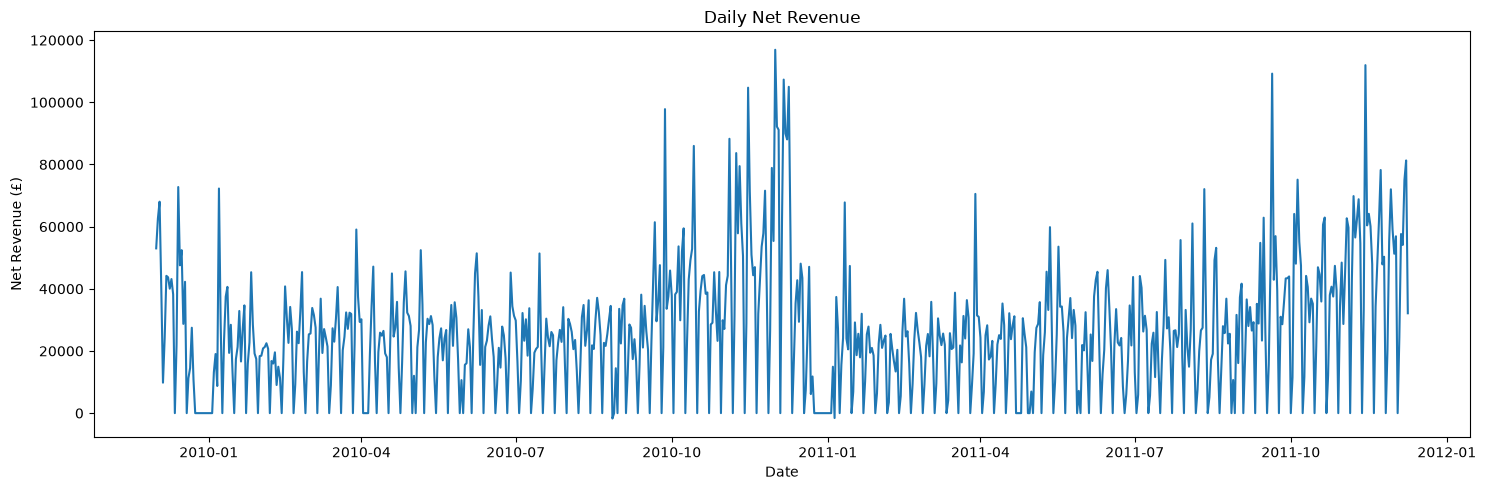

In [8]:
# Daily Revenue Trend
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    daily["date"],
    daily["net_revenue"],
)

plt.title(
    "Daily Net Revenue"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue (£)")

plt.tight_layout()
plt.show()

In [9]:
# Daily Revenue Statistics
daily[
    [
        "gross_revenue",
        "return_revenue",
        "net_revenue",
    ]
].describe().T

print(
    "Negative net-revenue days:",
    (daily["net_revenue"] < 0).sum(),
)

print(
    "Zero net-revenue days:",
    (daily["net_revenue"] == 0).sum(),
)

Negative net-revenue days: 2
Zero net-revenue days: 135


In [10]:
# Monthly Revenue
monthly = (
    daily
    .set_index("date")
    .resample("MS")
    .agg({
        "gross_revenue": "sum",
        "return_revenue": "sum",
        "net_revenue": "sum",
        "invoices": "sum",
    })
    .reset_index()
)
monthly.head()

,date,gross_revenue,return_revenue,net_revenue,invoices
0,2009-12-01,"822,483.95","-25,835.45","796,648.50","1,682.00"
1,2010-01-01,"651,155.11","-28,675.61","622,479.50","1,105.00"
2,2010-02-01,"551,504.73","-20,986.50","530,518.23","1,201.00"
3,2010-03-01,"830,915.26","-67,668.02","763,247.24","1,681.00"
4,2010-04-01,"678,875.25","-37,354.20","641,521.05","1,462.00"


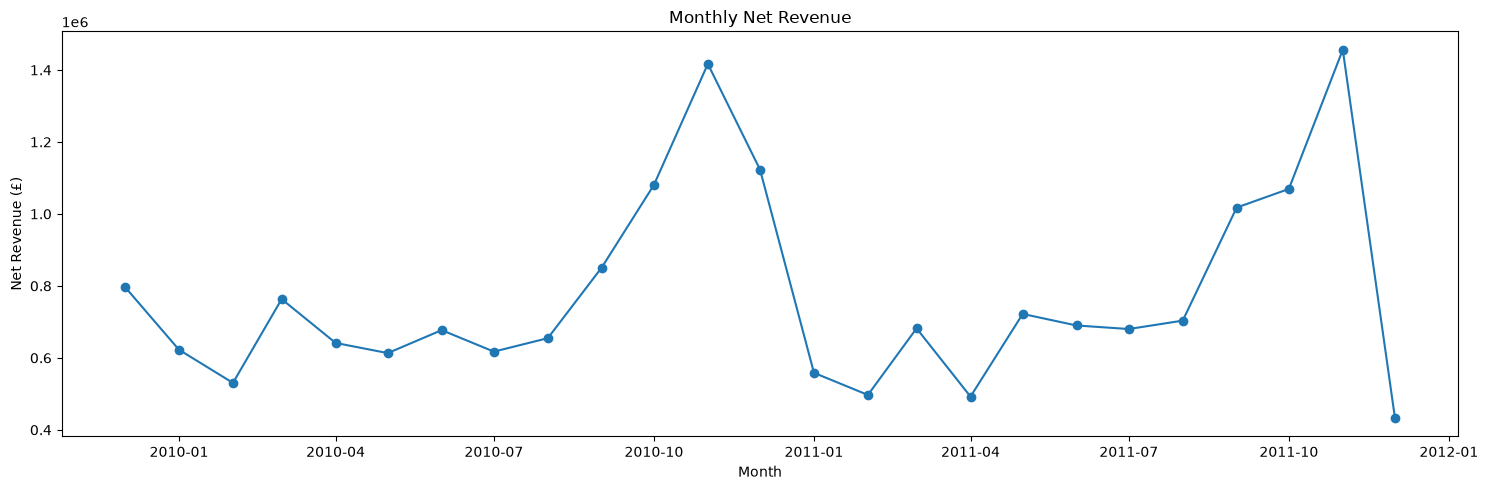

In [11]:
# Monthly Revenue Plot
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    monthly["date"],
    monthly["net_revenue"],
    marker="o",
)

plt.title(
    "Monthly Net Revenue"
)

plt.xlabel("Month")
plt.ylabel("Net Revenue (£)")

plt.tight_layout()
plt.show()

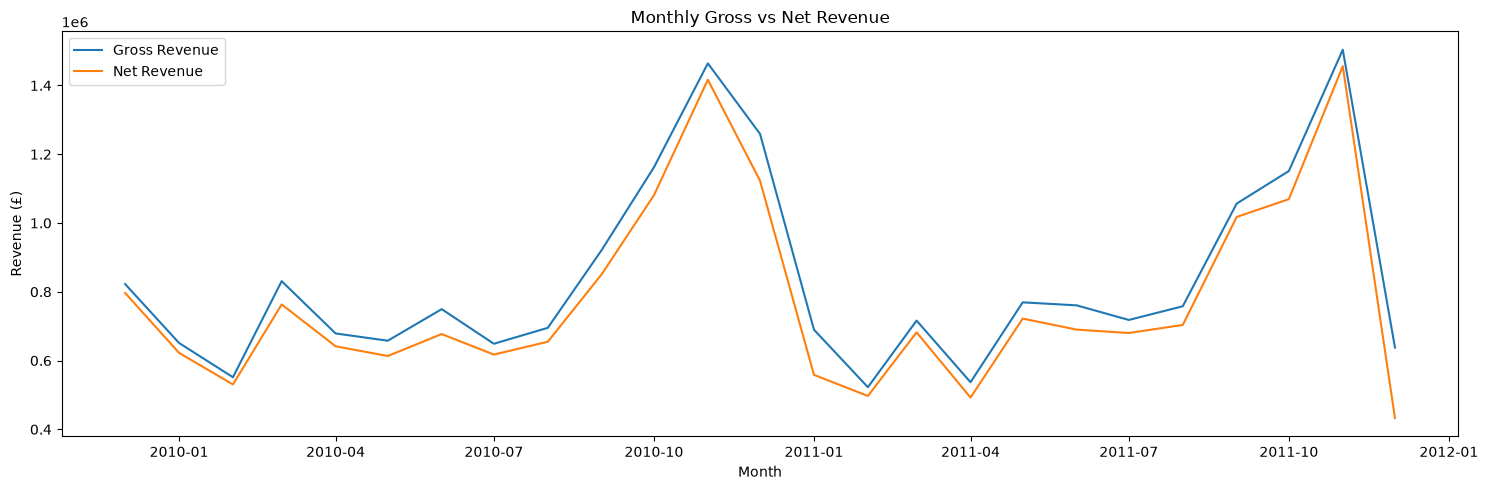

In [12]:
# Gross vs Net Revenue
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    monthly["date"],
    monthly["gross_revenue"],
    label="Gross Revenue",
)

plt.plot(
    monthly["date"],
    monthly["net_revenue"],
    label="Net Revenue",
)

plt.title(
    "Monthly Gross vs Net Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.legend()

plt.tight_layout()
plt.show()

In [13]:
# Month-over-Month Growth
monthly["mom_growth"] = (
    monthly["net_revenue"]
    .pct_change()
    * 100
)

monthly[
    [
        "date",
        "net_revenue",
        "mom_growth",
    ]
]

,date,net_revenue,mom_growth
0,2009-12-01,"796,648.50",NaN
1,2010-01-01,"622,479.50",-21.86
2,2010-02-01,"530,518.23",-14.77
3,2010-03-01,"763,247.24",43.87
4,2010-04-01,"641,521.05",-15.95
5,2010-05-01,"613,270.72",-4.40
6,2010-06-01,"677,073.87",10.40
7,2010-07-01,"617,365.48",-8.82
8,2010-08-01,"654,774.39",6.06
9,2010-09-01,"851,105.96",29.98


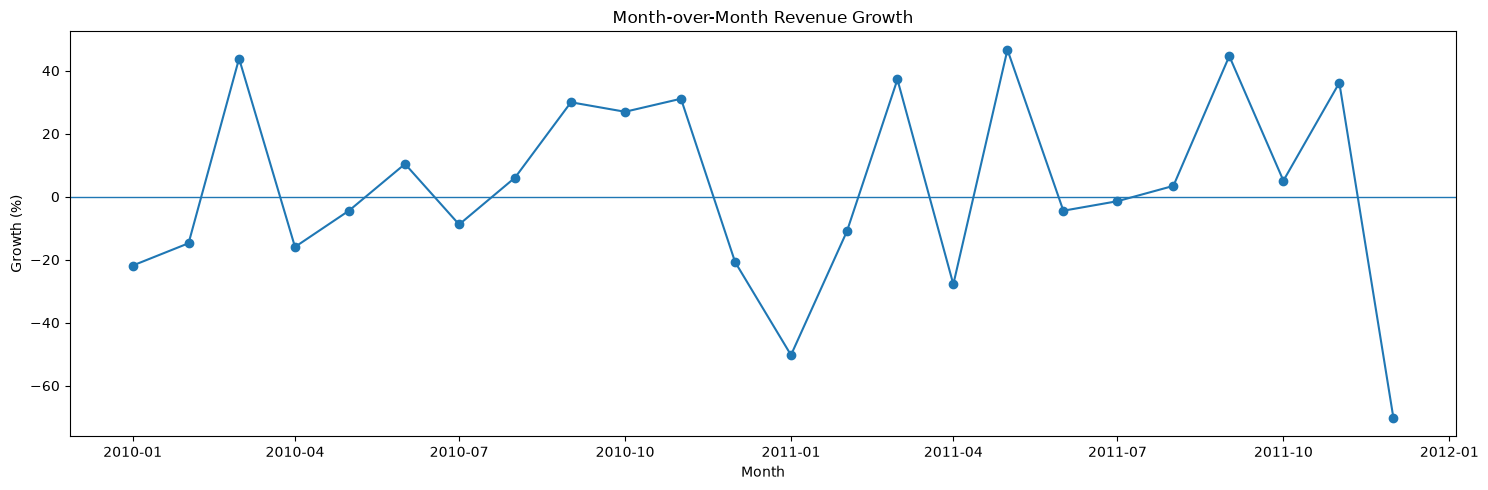

In [14]:
# MoM Growth Plot
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    monthly["date"],
    monthly["mom_growth"],
    marker="o",
)

plt.axhline(
    0,
    linewidth=1,
)

plt.title(
    "Month-over-Month Revenue Growth"
)

plt.xlabel("Month")
plt.ylabel("Growth (%)")

plt.tight_layout()
plt.show()

In [15]:
# Year-over-Year Growth
monthly["yoy_growth"] = (
    monthly["net_revenue"]
    .pct_change(periods=12)
    * 100
)

monthly[
    [
        "date",
        "net_revenue",
        "yoy_growth",
    ]
]

,date,net_revenue,yoy_growth
0,2009-12-01,"796,648.50",NaN
1,2010-01-01,"622,479.50",NaN
2,2010-02-01,"530,518.23",NaN
3,2010-03-01,"763,247.24",NaN
4,2010-04-01,"641,521.05",NaN
5,2010-05-01,"613,270.72",NaN
6,2010-06-01,"677,073.87",NaN
7,2010-07-01,"617,365.48",NaN
8,2010-08-01,"654,774.39",NaN
9,2010-09-01,"851,105.96",NaN


In [16]:
# Yearly Revenue
yearly = (
    daily
    .set_index("date")
    ["net_revenue"]
    .resample("YS")
    .sum()
    .reset_index()
)

yearly




,date,net_revenue
0,2009-01-01,"796,648.50"
1,2010-01-01,"9,591,655.55"
2,2011-01-01,"9,001,425.46"


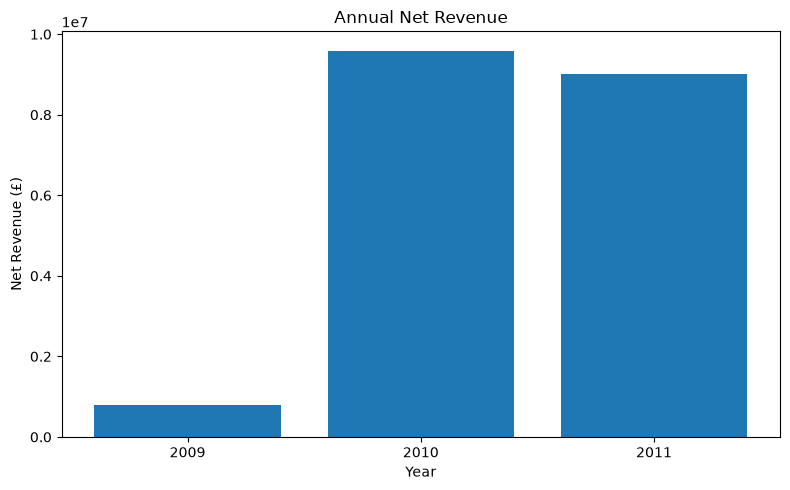

In [17]:
# Plot
plt.figure(
    figsize=(8, 5)
)

plt.bar(
    yearly["date"].dt.year.astype(str),
    yearly["net_revenue"],
)

plt.title(
    "Annual Net Revenue"
)

plt.xlabel("Year")
plt.ylabel("Net Revenue (£)")

plt.tight_layout()
plt.show()

In [18]:
# Country Analysis
country_sales = (
    sales
    .groupby(
        "country",
        as_index=False,
    )
    .agg(
        revenue=(
            "line_revenue",
            "sum",
        ),

        invoices=(
            "invoice_no",
            "nunique",
        ),

        customers=(
            "customer_id",
            "nunique",
        ),
    )
)

# Sort
country_sales = (
    country_sales
    .sort_values(
        "revenue",
        ascending=False,
    )
)

country_sales.head(10)

,country,revenue,invoices,customers
40,United Kingdom,"17,814,055.93",36537,5350
11,EIRE,"664,050.09",626,5
26,Netherlands,"554,230.69",228,22
15,Germany,"430,703.79",789,107
14,France,"356,746.51",622,95
0,Australia,"169,900.61",95,15
34,Spain,"109,127.21",154,41
36,Switzerland,"100,988.99",93,22
35,Sweden,"91,869.82",105,19
10,Denmark,"69,862.19",43,12


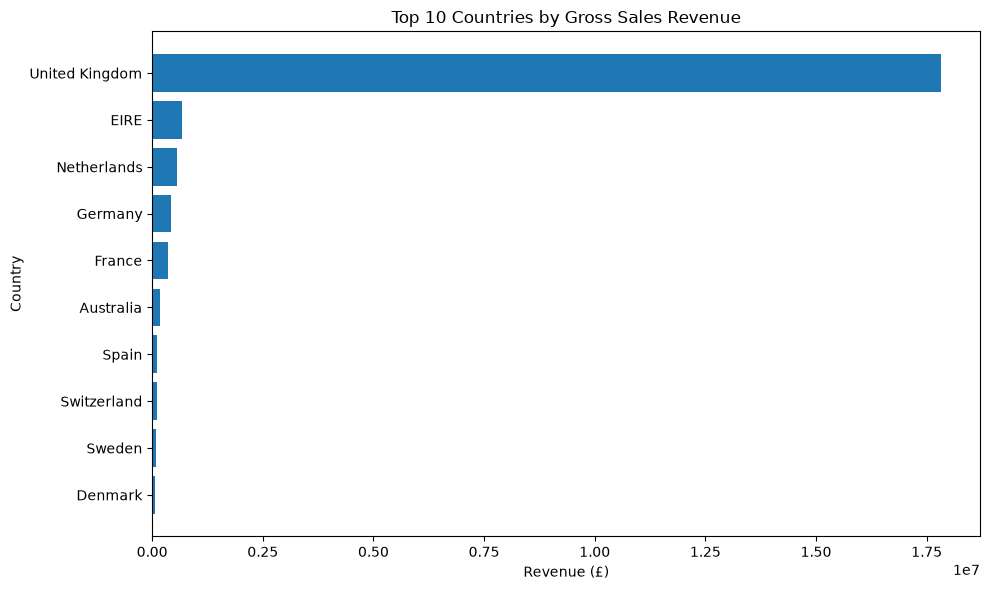

In [19]:
# Top 10 Countries
top_countries = (
    country_sales
    .head(10)
    .sort_values("revenue")
)

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    top_countries["country"],
    top_countries["revenue"],
)

plt.title(
    "Top 10 Countries by Gross Sales Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [20]:
# UK Revenue Concentration
uk_revenue = (
    country_sales.loc[
        country_sales["country"]
        .str.upper()
        .eq("UNITED KINGDOM"),
        "revenue",
    ]
    .sum()
)

country_total = (
    country_sales["revenue"].sum()
)

uk_share = (
    uk_revenue
    /
    country_total
)

print(
    f"UK revenue share: "
    f"{uk_share:.2%}"
)

UK revenue share: 85.18%


In [21]:
# Product Analysis
product_sales = (
    sales
    .groupby(
        [
            "stock_code",
            "description",
        ],
        as_index=False,
    )
    .agg(
        revenue=(
            "line_revenue",
            "sum",
        ),

        quantity=(
            "quantity",
            "sum",
        ),

        invoices=(
            "invoice_no",
            "nunique",
        ),
    )
)

# Sort
product_sales = (
    product_sales
    .sort_values(
        "revenue",
        ascending=False,
    )
)

product_sales.head(10)

,stock_code,description,revenue,quantity,invoices
1869,22423,REGENCY CAKESTAND 3 TIER,"344,069.30",27536,3918
5395,M,Manual,"340,342.68",9753,788
5387,DOT,DOTCOM POSTAGE,"322,657.48",1436,1415
4797,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"266,582.35",96563,5455
3329,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1
4772,85099B,JUMBO BAG RED RETROSPOT,"150,640.27",79117,3269
3674,47566,PARTY BUNTING,"149,109.35",28362,2674
4502,84879,ASSORTED COLOUR BIRD ORNAMENT,"131,817.81",81590,2807
5397,POST,POSTAGE,"127,597.42",5461,1851
1459,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"123,002.89",36534,2018


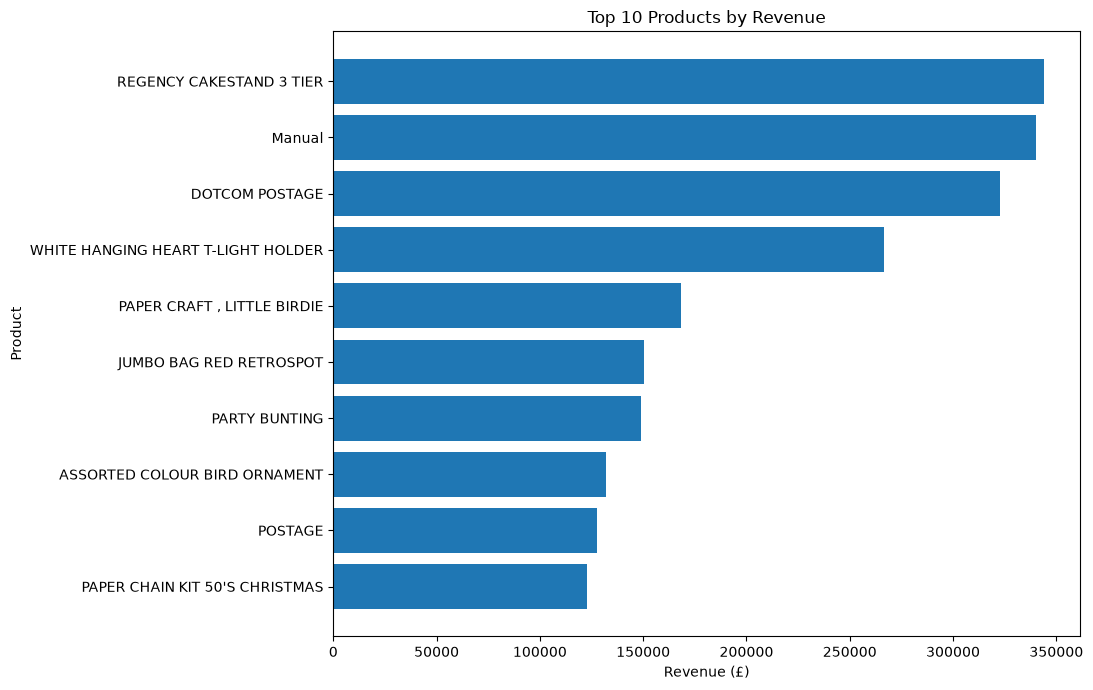

In [22]:
# Top 10 Products by Revenue
top_products = (
    product_sales
    .head(10)
    .sort_values("revenue")
)

plt.figure(
    figsize=(11, 7)
)

plt.barh(
    top_products["description"],
    top_products["revenue"],
)

plt.title(
    "Top 10 Products by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [23]:
# Top Products by Quantity
top_quantity_products = (
    product_sales
    .sort_values(
        "quantity",
        ascending=False,
    )
    .head(10)
)

top_quantity_products[
    [
        "description",
        "quantity",
        "revenue",
    ]
]

,description,quantity,revenue
4078,WORLD WAR 2 GLIDERS ASSTD DESIGNS,109898,"25,197.98"
4797,WHITE HANGING HEART T-LIGHT HOLDER,96563,"266,582.35"
4502,ASSORTED COLOUR BIRD ORNAMENT,81590,"131,817.81"
3329,"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60"
4772,JUMBO BAG RED RETROSPOT,79117,"150,640.27"
2784,MEDIUM CERAMIC TOP STORAGE JAR,78033,"81,700.92"
116,BROCADE RING PURSE,71394,"14,948.75"
1368,PACK OF 60 PINK PAISLEY CAKE CASES,56625,"28,413.63"
4641,60 TEATIME FAIRY CAKE CASES,54537,"27,321.37"
1587,SMALL POPCORN HOLDER,49922,"44,068.03"


In [24]:
# Product Revenue Concentration
top_10_revenue = (
    product_sales
    .head(10)["revenue"]
    .sum()
)

all_product_revenue = (
    product_sales[
        "revenue"
    ].sum()
)

top_10_share = (
    top_10_revenue
    /
    all_product_revenue
)

print(
    f"Top 10 product revenue share: "
    f"{top_10_share:.2%}"
)

Top 10 product revenue share: 10.16%


In [27]:
# Customer Analysis
known_customer_sales = (
    sales[
        sales["customer_id"].notna()
    ]
    .copy()
)
# Aggregate
customer_sales = (
    known_customer_sales
    .groupby(
        "customer_id",
        as_index=False,
    )
    .agg(
        revenue=(
            "line_revenue",
            "sum",
        ),

        invoices=(
            "invoice_no",
            "nunique",
        ),

        quantity=(
            "quantity",
            "sum",
        ),
    )
)
# Top Customers
top_customers = (
    customer_sales
    .sort_values(
        "revenue",
        ascending=False,
    )
    .head(10)
)

top_customers

,customer_id,revenue,invoices,quantity
5692,"18,102.00","608,821.65",145,188340
2277,"14,646.00","528,602.52",151,367193
1789,"14,156.00","313,759.82",156,165873
2538,"14,911.00","295,832.39",398,149949
5050,"17,450.00","246,813.09",51,84700
1331,"13,694.00","196,482.81",143,189205
5109,"17,511.00","175,603.55",60,119656
4061,"16,446.00","168,472.50",2,80997
4295,"16,684.00","147,142.77",55,104810
68,"12,415.00","144,458.37",28,91447


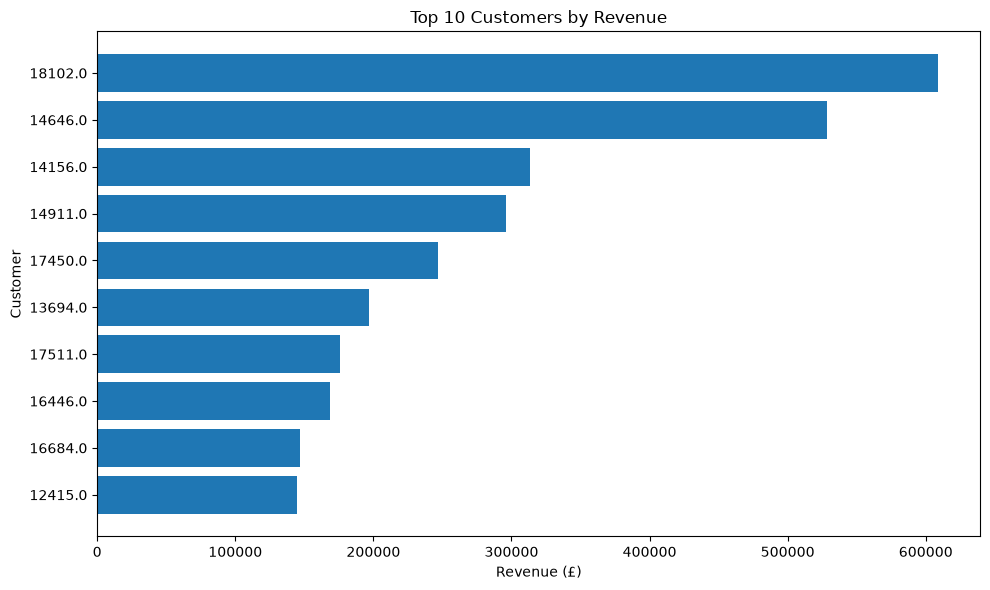

In [28]:
# Plot
plot_customers = (
    top_customers
    .sort_values("revenue")
)

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    plot_customers[
        "customer_id"
    ].astype(str),

    plot_customers[
        "revenue"
    ],
)

plt.title(
    "Top 10 Customers by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Customer")

plt.tight_layout()
plt.show()

In [29]:
# Customer Revenue Distribution
customer_sales[
    "revenue"
].describe(
    percentiles=[
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
    ]
)

count     5,878.00
mean      3,008.75
std      14,731.92
min           2.95
25%         345.12
50%         887.39
75%       2,298.01
90%       5,557.65
95%       9,504.78
99%      29,710.55
max     608,821.65
Name: revenue, dtype: float64

In [30]:
# Customer Concentration
# Top 10 customer contribution
top_customer_revenue = (
    customer_sales
    .nlargest(
        10,
        "revenue",
    )["revenue"]
    .sum()
)

customer_total_revenue = (
    customer_sales[
        "revenue"
    ].sum()
)

top_customer_share = (
    top_customer_revenue
    /
    customer_total_revenue
)

print(
    f"Top 10 customer revenue share: "
    f"{top_customer_share:.2%}"
)

Top 10 customer revenue share: 15.98%


In [31]:
# Return Analysis
returns[
    [
        "invoice_no",
        "stock_code",
        "description",
        "quantity",
        "unit_price",
        "return_revenue",
    ]
].head()

,invoice_no,stock_code,description,quantity,unit_price,return_revenue
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2.95,-35.40
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,1.65,-9.90
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,4.25,-17.00
3,C489449,21896,POTTING SHED TWINE,-6,2.10,-12.60
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2.95,-35.40


In [32]:
# Total Return Value
total_return_value = (
    returns[
        "return_revenue"
    ]
    .abs()
    .sum()
)

print(
    f"Total Return Value: "
    f"£{total_return_value:,.2f}"
)

Total Return Value: £1,524,161.95


In [33]:
# Products with Highest Return Value
product_returns = (
    returns
    .groupby(
        [
            "stock_code",
            "description",
        ],
        as_index=False,
    )
    .agg(
        return_value=(
            "return_revenue",
            lambda x: x.abs().sum(),
        ),

        return_quantity=(
            "quantity",
            lambda x: x.abs().sum(),
        ),
    )
)

# sort
product_returns = (
    product_returns
    .sort_values(
        "return_value",
        ascending=False,
    )
)

product_returns.head(10)

,stock_code,description,return_value,return_quantity
3071,M,Manual,"424,246.80",5451
3064,AMAZONFEE,AMAZON FEE,"294,772.71",39
2171,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995
1912,23166,MEDIUM CERAMIC TOP STORAGE JAR,"77,479.64",74494
3065,BANK CHARGES,Bank Charges,"36,096.87",77
1305,22423,REGENCY CAKESTAND 3 TIER,"16,724.10",1466
3073,POST,POSTAGE,"15,256.42",303
3068,D,Discount,"13,882.43",3068
2848,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"9,389.65",3638
3067,CRUK,CRUK Commission,"7,933.43",16


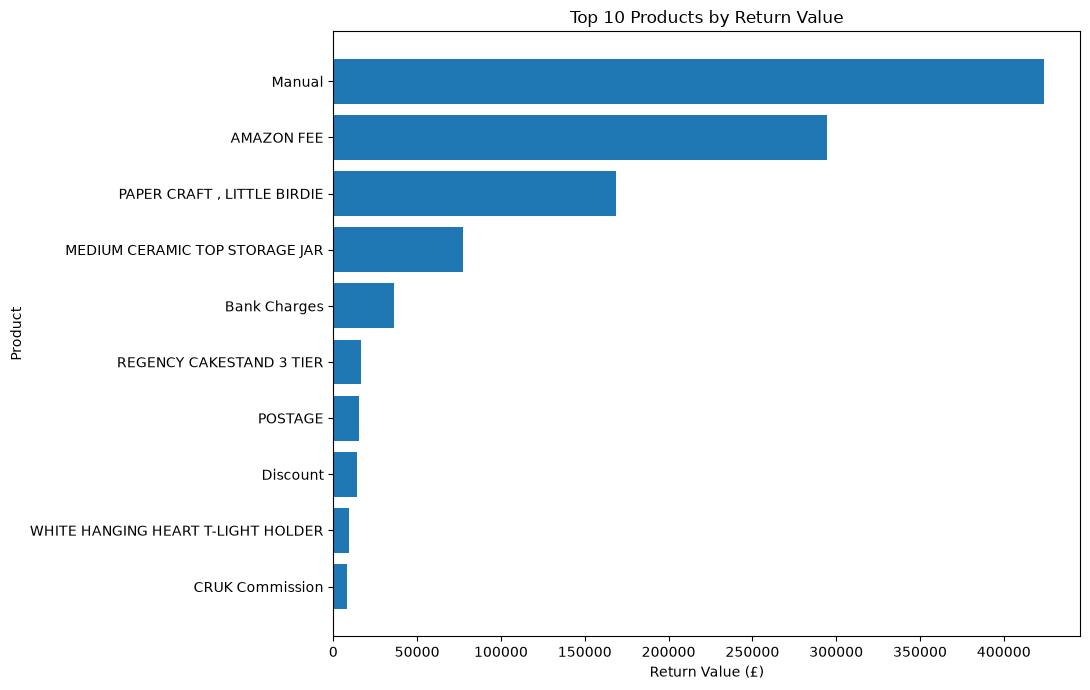

In [34]:
# Top Returned Products
top_returns = (
    product_returns
    .head(10)
    .sort_values("return_value")
)

plt.figure(
    figsize=(11, 7)
)

plt.barh(
    top_returns["description"],
    top_returns["return_value"],
)

plt.title(
    "Top 10 Products by Return Value"
)

plt.xlabel("Return Value (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [35]:
# Return Rate theo Product
product_performance = (
    product_sales[
        [
            "stock_code",
            "description",
            "revenue",
        ]
    ]
    .merge(
        product_returns[
            [
                "stock_code",
                "return_value",
            ]
        ],
        on="stock_code",
        how="left",
    )
)
# Fill
product_performance[
    "return_value"
] = (
    product_performance[
        "return_value"
    ].fillna(0)
)

# Rate
product_performance[
    "return_rate"
] = (
    product_performance[
        "return_value"
    ]
    /
    product_performance[
        "revenue"
    ]
)
# Top Rate
meaningful_products = (
    product_performance[
        product_performance[
            "revenue"
        ] >= 1000
    ]
)
meaningful_products[
    [
        "description",
        "revenue",
        "return_value",
        "return_rate",
    ]
].sort_values(
    "return_rate",
    ascending=False,
).head(10)

,description,revenue,return_value,return_rate
98,AMAZON FEE,"34,009.13","294,772.71",8.67
2772,GIN AND TONIC DIET METAL SIGN,"1,237.50","3,785.58",3.06
1481,COLOURED GLASS STAR T-LIGHT HOLDER,"3,580.96","6,976.41",1.95
2132,EAU DE NIL DINER WALL CLOCK,"2,067.20","2,662.20",1.29
1,Manual,"340,342.68","424,246.80",1.25
4,"PAPER CRAFT , LITTLE BIRDIE","168,469.60","168,469.60",1.00
2466,BLACK CHERRY LIGHTS,"1,565.70","1,557.20",0.99
13,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92","77,479.64",0.95
2588,RETRO SPOT PARTY BAG + STICKER SET,"1,412.25","1,253.85",0.89
986,PANTRY CHOPPING BOARD,"5,868.50","4,803.06",0.82


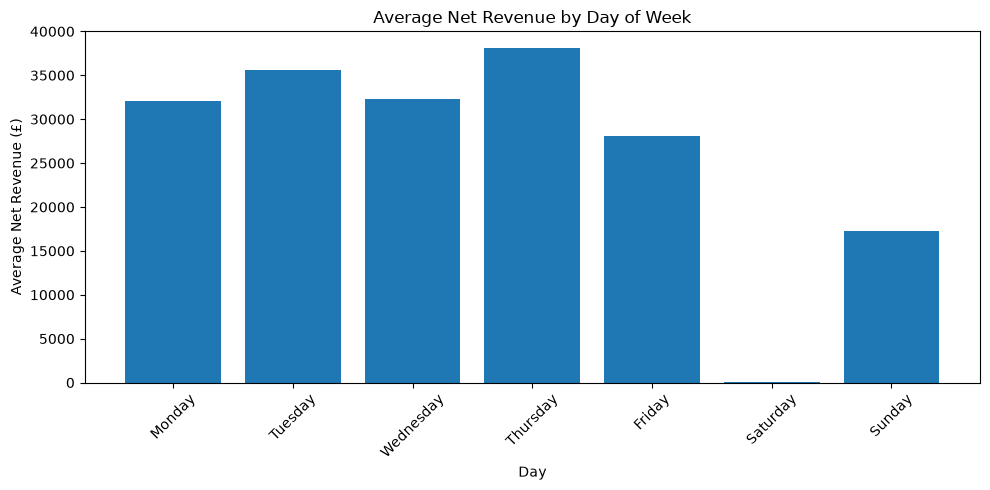

In [36]:
# Weekday Seasonality
daily["day_name"] = (
    daily["date"]
    .dt.day_name()
)
# create order 
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

# Average
weekday_revenue = (
    daily
    .groupby(
        "day_name"
    )["net_revenue"]
    .mean()
    .reindex(
        weekday_order
    )
)

# Plot
plt.figure(
    figsize=(10, 5)
)

plt.bar(
    weekday_revenue.index,
    weekday_revenue.values,
)

plt.title(
    "Average Net Revenue by Day of Week"
)

plt.xlabel("Day")
plt.ylabel("Average Net Revenue (£)")

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

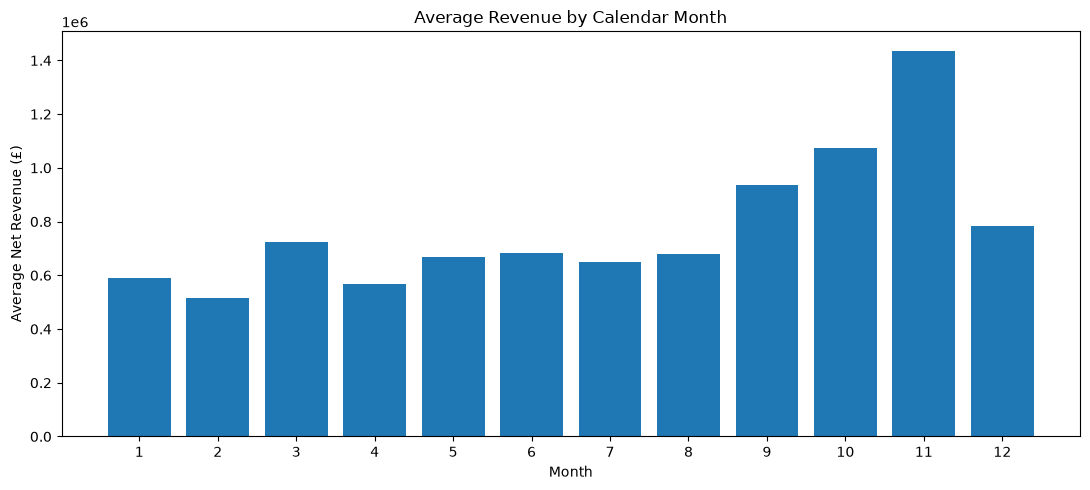

In [37]:
# Monthly Seasonality
daily["month_number"] = (
    daily["date"].dt.month
)

daily["month_name"] = (
    daily["date"]
    .dt.month_name()
)

month_year = (
    daily
    .set_index("date")
    ["net_revenue"]
    .resample("MS")
    .sum()
    .reset_index()
)

month_year["month_number"] = (
    month_year[
        "date"
    ].dt.month
)

# Average by calendar month
seasonal_month = (
    month_year
    .groupby(
        "month_number"
    )["net_revenue"]
    .mean()
)
# Plot
plt.figure(
    figsize=(11, 5)
)

plt.bar(
    seasonal_month.index,
    seasonal_month.values,
)

plt.title(
    "Average Revenue by Calendar Month"
)

plt.xlabel("Month")
plt.ylabel("Average Net Revenue (£)")

plt.xticks(
    range(1, 13)
)

plt.tight_layout()
plt.show()

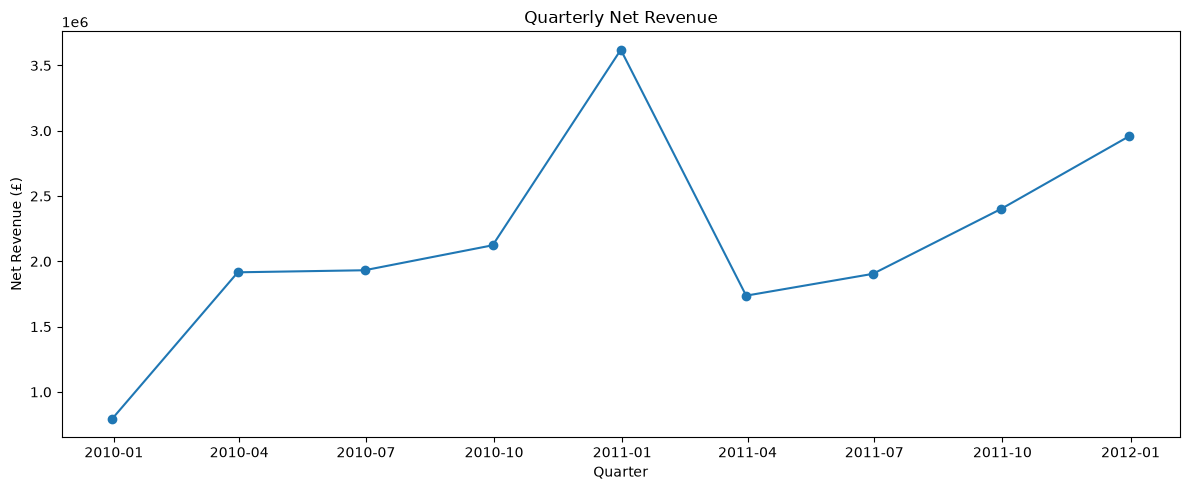

In [38]:
# Quarterly Revenue
quarterly = (
    daily
    .set_index("date")
    ["net_revenue"]
    .resample("QE")
    .sum()
    .reset_index()
)
# Plot
plt.figure(
    figsize=(12, 5)
)

plt.plot(
    quarterly["date"],
    quarterly["net_revenue"],
    marker="o",
)

plt.title(
    "Quarterly Net Revenue"
)

plt.xlabel("Quarter")
plt.ylabel("Net Revenue (£)")

plt.tight_layout()
plt.show()

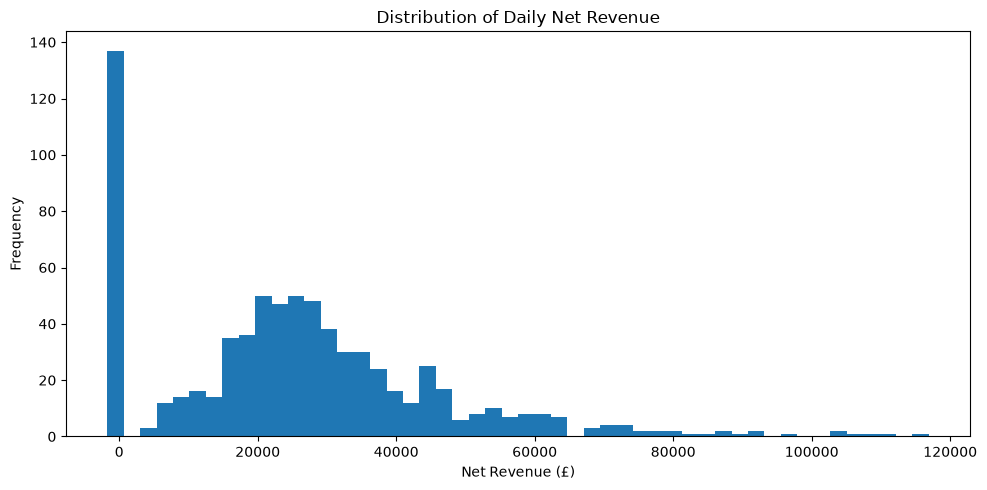

In [39]:
# Revenue Distribution
plt.figure(
    figsize=(10, 5)
)

plt.hist(
    daily["net_revenue"],
    bins=50,
)

plt.title(
    "Distribution of Daily Net Revenue"
)

plt.xlabel("Net Revenue (£)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [40]:
daily["net_revenue"].skew()

np.float64(1.0382120884766481)

In [41]:
# Quantile Analysis
daily[
    "net_revenue"
].quantile(
    [
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99,
    ]
)

0.01        0.00
0.05        0.00
0.25   13,210.78
0.50   24,708.59
0.75   35,687.91
0.95   62,375.01
0.99   91,786.81
Name: net_revenue, dtype: float64

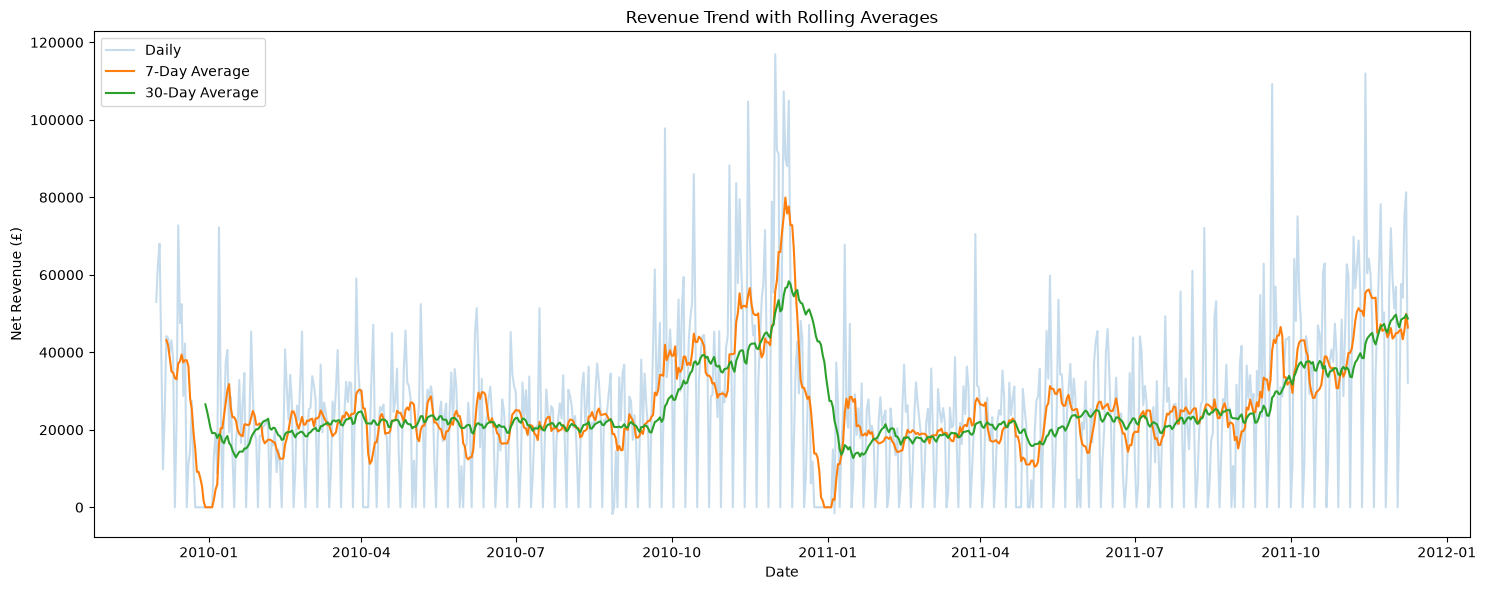

In [42]:
# Rolling Average
daily[
    "rolling_7d"
] = (
    daily[
        "net_revenue"
    ]
    .rolling(
        window=7,
    )
    .mean()
)

daily[
    "rolling_30d"
] = (
    daily[
        "net_revenue"
    ]
    .rolling(
        window=30,
    )
    .mean()
)
# Plot
plt.figure(
    figsize=(15, 6)
)

plt.plot(
    daily["date"],
    daily["net_revenue"],
    alpha=0.25,
    label="Daily",
)

plt.plot(
    daily["date"],
    daily["rolling_7d"],
    label="7-Day Average",
)

plt.plot(
    daily["date"],
    daily["rolling_30d"],
    label="30-Day Average",
)

plt.title(
    "Revenue Trend with Rolling Averages"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue (£)")

plt.legend()

plt.tight_layout()
plt.show()

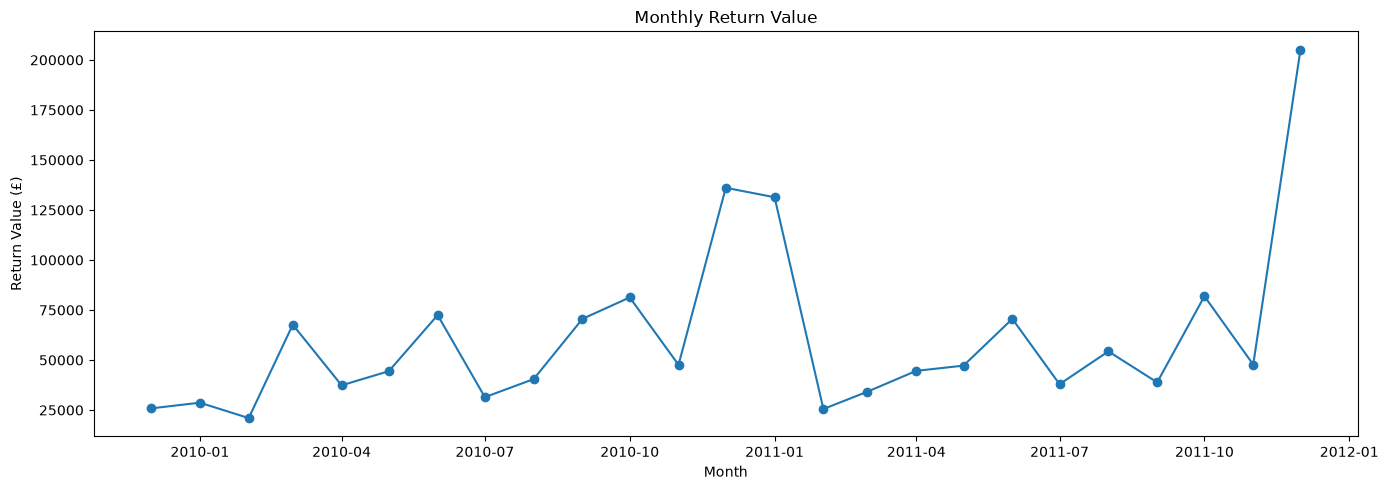

In [43]:
# Monthly Return Trend
monthly_returns = (
    daily
    .set_index("date")
    ["return_revenue"]
    .resample("MS")
    .sum()
    .abs()
    .reset_index()
)
# Plot
plt.figure(
    figsize=(14, 5)
)

plt.plot(
    monthly_returns["date"],
    monthly_returns["return_revenue"],
    marker="o",
)

plt.title(
    "Monthly Return Value"
)

plt.xlabel("Month")
plt.ylabel("Return Value (£)")

plt.tight_layout()
plt.show()

In [44]:
# Revenue vs Return relationship
monthly_analysis = (
    monthly[
        [
            "date",
            "gross_revenue",
            "return_revenue",
            "net_revenue",
        ]
    ]
    .copy()
)

monthly_analysis[
    "return_value"
] = (
    monthly_analysis[
        "return_revenue"
    ].abs()
)

monthly_analysis[
    "return_rate"
] = np.where(
    monthly_analysis[
        "gross_revenue"
    ] > 0,

    monthly_analysis[
        "return_value"
    ]
    /
    monthly_analysis[
        "gross_revenue"
    ],

    0,
)

monthly_analysis[
    [
        "date",
        "gross_revenue",
        "return_value",
        "return_rate",
    ]
]
# Revenue Concentration — Pareto Analysis

pareto_products = (
    product_sales
    .sort_values(
        "revenue",
        ascending=False,
    )
    .copy()
)

pareto_products[
    "revenue_share"
] = (
    pareto_products[
        "revenue"
    ]
    /
    pareto_products[
        "revenue"
    ].sum()
)

pareto_products[
    "cumulative_share"
] = (
    pareto_products[
        "revenue_share"
    ]
    .cumsum()
)

# Find a products which created 80% revenue
products_for_80 = (
    pareto_products[
        pareto_products[
            "cumulative_share"
        ] <= 0.80
    ]
    .shape[0]
)

total_product_count = (
    len(pareto_products)
)

print(
    f"Products contributing "
    f"approximately 80% of revenue: "
    f"{products_for_80:,} / "
    f"{total_product_count:,}"
)

Products contributing approximately 80% of revenue: 1,133 / 5,402


In [45]:
# Business Insights Summary
best_country = (
    country_sales.iloc[0]
)

best_product = (
    product_sales.iloc[0]
)

best_month = (
    monthly.loc[
        monthly[
            "net_revenue"
        ].idxmax()
    ]
)

worst_month = (
    monthly.loc[
        monthly[
            "net_revenue"
        ].idxmin()
    ]
)

print("=" * 70)
print("BUSINESS INSIGHTS SUMMARY")
print("=" * 70)

print(
    f"Net Revenue: "
    f"£{total_net_revenue:,.2f}"
)

print(
    f"Overall Return Rate: "
    f"{overall_return_rate:.2%}"
)

print(
    f"Average Order Value: "
    f"£{average_order_value:,.2f}"
)

print(
    f"Top Country: "
    f"{best_country['country']}"
)

print(
    f"Top Product: "
    f"{best_product['description']}"
)

print(
    f"Highest Revenue Month: "
    f"{best_month['date']:%Y-%m}"
)

print(
    f"Lowest Revenue Month: "
    f"{worst_month['date']:%Y-%m}"
)

print(
    f"UK Revenue Share: "
    f"{uk_share:.2%}"
)

print(
    f"Top 10 Product Share: "
    f"{top_10_share:.2%}"
)

BUSINESS INSIGHTS SUMMARY
Net Revenue: £19,389,729.52
Overall Return Rate: 7.29%
Average Order Value: £521.82
Top Country: United Kingdom
Top Product: REGENCY CAKESTAND 3 TIER
Highest Revenue Month: 2011-11
Lowest Revenue Month: 2011-12
UK Revenue Share: 85.18%
Top 10 Product Share: 10.16%


In [46]:
# Create Analytics Tables for Power BI


from ml.config import (
    ANALYTICS_DIR,
)
ANALYTICS_DIR.exists()
ANALYTICS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
monthly.to_csv(
    ANALYTICS_DIR
    / "monthly_revenue.csv",
    index=False,
)

country_sales.to_csv(
    ANALYTICS_DIR
    / "country_performance.csv",
    index=False,
)

product_sales.to_csv(
    ANALYTICS_DIR
    / "product_performance.csv",
    index=False,
)

customer_sales.to_csv(
    ANALYTICS_DIR
    / "customer_performance.csv",
    index=False,
)

product_returns.to_csv(
    ANALYTICS_DIR
    / "product_returns.csv",
    index=False,
)

## Business Findings

### 1. Revenue Performance

The business generated £[NET_REVENUE] in net revenue during
the observed period.

Monthly revenue analysis indicates [growth / decline / seasonal]
patterns, with the strongest performance observed during [PERIOD].

### 2. Geographic Concentration

The United Kingdom contributed approximately [X]% of gross sales
revenue, indicating a significant concentration in the domestic market.

This creates strong domestic-market performance but also potential
geographic concentration risk.

### 3. Product Performance

The highest-performing products contributed a significant share
of total sales.

Approximately [N] products generated around 80% of product revenue,
suggesting [high/moderate/low] product concentration.

### 4. Customer Concentration

Revenue is unevenly distributed across customers, with a relatively
small group of high-value customers contributing a meaningful share
of identified-customer revenue.

### 5. Returns

Returns and cancellations reduced gross revenue by approximately
[X]%.

Products with unusually high return rates should be investigated
for potential product-quality, fulfillment, or product-description
issues.

### 6. Seasonality

Revenue varies across weekdays and calendar months.

The observed seasonal patterns suggest that calendar and lag-based
features should be incorporated into the forecasting models.

### 7. Forecasting Implications

The exploratory analysis indicates that revenue contains:

- Trend
- Weekly patterns
- Monthly/seasonal variation
- Outliers
- Return-related volatility
- Zero-sales calendar days

These characteristics will guide the time-series analysis and
feature-engineering strategy in the next step.